On modélise un qunatum reservoir.

Le but est de déterminer quel est la meilleure heuristique quantique pour faire aggrandir l'espace dans lequel vit les X_i

Notre problématique est d'essayer d'avoir le meilleur training quantique pour nos données.

Faut-il beaucoup/pas beaucoup d'intrication ? Mettre des R_z ?

## Génération des paramètres

(Par Victor)

In [23]:


from scipy.integrate import odeint
import matplotlib.pyplot as plt
import numpy as np
import random


# These are our constants
N = 8 # Number of variables
F = 8  # Forcing pour avoir génération chaotique


def L96(x, t):
    """Lorenz 96 model with constant forcing"""
    return (np.roll(x, -1) - np.roll(x, 2)) * np.roll(x, 1) - x + F


x0 = F * np.ones(N)  # Initial state (equilibrium)
x0[0] += 0.01*random.uniform(0,1)  # Add small perturbation to the first variable
t = np.arange(0.0, 30.0, 0.01)

xs = odeint(L96, x0, t)
x_data=xs/np.max(np.abs(xs))



## Générateur de circuits paramétrés
Structure : `H` → pour chaque couche d'intrication `l` ∈ [0, nb_ring) : (RY **données** si `l < nb_encode`, sinon RY **aléatoires**) → couche d'intrication (paramètre `I`) → RY aléatoires finaux.
Avec `nb_ring=3, nb_encode=2, I=0` on retrouve exactement ton circuit exemple.

In [24]:
import numpy as np
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.quantum_info import Statevector, partial_trace, entropy

def entangling_layer(qc, n, I, rng, gate="cx"):
    """I=0 : anneau (n portes). I=1 : toutes les paires (n(n-1)/2 portes).
    Entre les deux : l'anneau + une fraction I des paires restantes, tirées au hasard,
    puis ordre des portes mélangé."""
    ring = [(i, (i + 1) % n) for i in range(n)]
    ring_set = {frozenset(p) for p in ring}
    others = [(i, j) for i in range(n) for j in range(i + 1, n)
              if frozenset((i, j)) not in ring_set]
    n_extra = int(round(I * len(others)))
    extra = [others[k] for k in rng.choice(len(others), n_extra, replace=False)] if n_extra else []
    gates = ring + extra
    if extra:
        gates = [gates[k] for k in rng.permutation(len(gates))]
    for a, b in gates:
        getattr(qc, gate)(a, b)

def encode_layer(qc, x, lam, n):
    """ On encode 
    """
    # feature k -> qubit k % n  (si n < K, plusieurs features partagent un qubit)
    for k in range(len(x)):
        qc.ry(lam * x[k], k % n)

def build_circuit(K=8, n_qubits=None, I=0.0, nb_ring=3, nb_encode=2,
                  lam=0.01, alpha_range=2*np.pi, seed=0, I_seeds=None,
                  gate="cx", shared_alpha=True):
    """ K: longueur de X_i, n_qubits > K, 0<I<1, nb_ring : nb de fois qu'on applqiue des rings ;
      nb_encode : nb de fois qu'on encore, après on applique des truc aléatoires dépendant de SEED (il faut à chaque fois la meme chose)
      Par défaut on applique des cx mais il est plus naturel ici d'utiliser des cz ?
      si sahred_alpha:True, toujours le même vecteur aléatoire appiqué à chq layer
      lam : facteur d'échelle
    """
    
    n = n_qubits or K
    nb_encode = min(nb_encode, nb_ring)

    if I_seeds is None or isinstance(I_seeds, (int, np.integer)):
        I_seeds = np.random.default_rng(I_seeds).integers(0, 2**32, nb_ring).tolist()
    else:
        I_seeds = [int(s) for s in I_seeds]
        assert len(I_seeds) == nb_ring, "I_seeds doit contenir nb_ring entiers"

    rng = np.random.default_rng(seed)
    alpha = rng.uniform(0, alpha_range, n)
    x = ParameterVector("x", K)

    qc = QuantumCircuit(n)
    qc.h(range(n))
    for layer in range(nb_ring):
        qc.barrier()
        if layer < nb_encode:
            encode_layer(qc, x, lam, n)
        else:
            a = alpha if shared_alpha else rng.uniform(0, alpha_range, n)
            for q in range(n): qc.ry(a[q], q)
        entangling_layer(qc, n, I, np.random.default_rng(I_seeds[layer]), gate)
    a = alpha if shared_alpha else rng.uniform(0, alpha_range, n)
    for q in range(n): qc.ry(a[q], q)

    def circuit(u, state=False):
        sv = Statevector(qc.assign_parameters({x: np.asarray(u)}))
        return sv if state else sv.probabilities()

    return circuit,qc , I_seeds

circuit, qc, I_seeds = build_circuit(K=8, I=0.3, nb_ring=3, nb_encode=2, lam=0.1)
print(I_seeds)                       # ex. [2810034, 913377, 4021100]

# Rejouer exactement le même circuit
circuit2, qc2, _ = build_circuit(K=8, I=0.3, nb_ring=3, nb_encode=2, lam=0.1, I_seeds=I_seeds)

# Garder le même motif d'intrication en variant I ou alpha
circuit3, _, _ = build_circuit(K=8, I=0.6, nb_ring=3, nb_encode=2, lam=0.1, I_seeds=I_seeds, seed=1)
print(qc.count_ops()); qc.draw()

[2955202078, 3495063446, 483306857]
OrderedDict([('cx', 42), ('ry', 32), ('h', 8), ('barrier', 3)])


┌───┐ ░ ┌──────────────┐               ┌───┐                              »
q_0: ┤ H ├─░─┤ Ry(0.1*x[0]) ├───────■───────┤ X ├──■─────────■─────────────────»
     ├───┤ ░ ├──────────────┤       │       └─┬─┘  │       ┌─┴─┐               »
q_1: ┤ H ├─░─┤ Ry(0.1*x[1]) ├───────┼─────────┼────┼────■──┤ X ├───────■────■──»
     ├───┤ ░ ├──────────────┤       │         │  ┌─┴─┐┌─┴─┐└───┘       │    │  »
q_2: ┤ H ├─░─┤ Ry(0.1*x[2]) ├───────┼─────────┼──┤ X ├┤ X ├──■────■────┼────┼──»
     ├───┤ ░ ├──────────────┤       │         │  └───┘└───┘  │  ┌─┴─┐┌─┴─┐  │  »
q_3: ┤ H ├─░─┤ Ry(0.1*x[3]) ├───────┼─────────┼────■────■────┼──┤ X ├┤ X ├──┼──»
     ├───┤ ░ ├──────────────┤       │         │    │  ┌─┴─┐  │  └───┘└───┘┌─┴─┐»
q_4: ┤ H ├─░─┤ Ry(0.1*x[4]) ├───────┼────■────┼────┼──┤ X ├──┼────────────┤ X ├»
     ├───┤ ░ ├──────────────┤       │  ┌─┴─┐  │    │  └───┘  │            └───┘»
q_5: ┤ H ├─░─┤ Ry(0.1*x[5]) ├──■────┼──┤ X ├──┼────┼─────────┼─────────────────»
     ├───┤ ░ ├──────────────┤┌─┴─┐┌─┴─┐└───┘  │  ┌─┴─┐       │                 »
q_6: ┤ H ├─░─┤ Ry(0.1*x[6]) ├┤ X ├┤ X ├───────┼──┤ X ├───────┼────■────────────»
     ├───┤ ░ ├──────────────┤└───┘└───┘       │  └───┘     ┌─┴─┐┌─┴─┐          »
q_7: ┤ H ├─░─┤ Ry(0.1*x[7]) ├─────────────────■────────────┤ X ├┤ X ├──────────»
     └───┘ ░ └──────────────┘                              └───┘└───┘          »
«      ░ ┌──────────────┐                              ┌───┐                ░ »
«q_0: ─░─┤ Ry(0.1*x[0]) ├──■───────────────────■───────┤ X ├────────────────░─»
«      ░ ├──────────────┤  │                 ┌─┴─┐     └─┬─┘                ░ »
«q_1: ─░─┤ Ry(0.1*x[1]) ├──┼─────────■────■──┤ X ├───────┼─────────■────────░─»
«      ░ ├──────────────┤  │       ┌─┴─┐  │  └───┘       │         │        ░ »
«q_2: ─░─┤ Ry(0.1*x[2]) ├──┼────■──┤ X ├──┼────■─────────┼─────────┼────────░─»
«      ░ ├──────────────┤  │  ┌─┴─┐└───┘  │    │         │       ┌─┴─┐      ░ »
«q_3: ─░─┤ Ry(0.1*x[3]) ├──┼──┤ X ├───────┼────┼─────────┼────■──┤ X ├──────░─»
«      ░ ├──────────────┤┌─┴─┐└───┘     ┌─┴─┐┌─┴─┐       │  ┌─┴─┐└───┘      ░ »
«q_4: ─░─┤ Ry(0.1*x[4]) ├┤ X ├──────────┤ X ├┤ X ├──■────┼──┤ X ├──■────────░─»
«      ░ ├──────────────┤└───┘          └───┘└───┘┌─┴─┐  │  └───┘  │        ░ »
«q_5: ─░─┤ Ry(0.1*x[5]) ├───────■─────────────────┤ X ├──┼─────────┼────■───░─»
«      ░ ├──────────────┤       │                 └───┘  │       ┌─┴─┐┌─┴─┐ ░ »
«q_6: ─░─┤ Ry(0.1*x[6]) ├──■────┼────────────────────────┼───────┤ X ├┤ X ├─░─»
«      ░ ├──────────────┤┌─┴─┐┌─┴─┐                      │       └───┘└───┘ ░ »
«q_7: ─░─┤ Ry(0.1*x[7]) ├┤ X ├┤ X ├──────────────────────■──────────────────░─»
«      ░ └──────────────┘└───┘└───┘                                         ░ »
«      ┌────────────┐               ┌───┐                                      »
«q_0: ─┤ Ry(4.0021) ├───────────────┤ X ├──■──────────────────────■────────────»
«      ├────────────┤               └─┬─┘┌─┴─┐                    │            »
«q_1: ─┤ Ry(1.6951) ├─────────────────┼──┤ X ├──────■─────────────┼─────────■──»
«     ┌┴────────────┤                 │  └───┘      │             │       ┌─┴─┐»
«q_2: ┤ Ry(0.25744) ├─────────────────┼────■────────┼─────────────┼───────┤ X ├»
«     ├─────────────┤                 │    │        │             │       └───┘»
«q_3: ┤ Ry(0.10385) ├──■──────────────┼────┼────────┼─────────────┼────────────»
«     └┬────────────┤  │              │    │        │           ┌─┴─┐          »
«q_4: ─┤ Ry(5.1099) ├──┼─────────■────┼────┼────────┼───────────┤ X ├──────────»
«      ├───────────┬┘┌─┴─┐     ┌─┴─┐  │    │        │           └───┘          »
«q_5: ─┤ Ry(5.735) ├─┤ X ├──■──┤ X ├──┼────┼────────┼──────────────────────────»
«      ├───────────┴┐└───┘┌─┴─┐└───┘  │    │      ┌─┴─┐     ┌────────────┐     »
«q_6: ─┤ Ry(3.8116) ├─────┤ X ├──■────┼────┼──────┤ X ├─────┤ Ry(3.8116) ├─────»
«      ├────────────┤     └───┘┌─┴─┐  │  ┌─┴─┐┌───┴───┴────┐└────────────┘     »
«q_7: ─┤ Ry(4.5836) ├──────────┤ X ├──■──┤ X ├┤ Ry(4.

In [25]:
def compute_states(circuit, X):
    """États exacts, calculés une seule fois (shape : N x 2^n)."""
    return np.array([circuit(u, state=True).data for u in X])

def features_from_states(psi, n, mode="probs", shots=None, seed=0):
    """mode : 'state' (idéal, non mesurable) | 'probs' | 'z' | 'zz' (= Z_i et Z_iZ_j, i<j)
    shots=None : valeurs exactes ; sinon : estimation à partir de `shots` bitstrings."""
    if mode == "state":
        return np.hstack([psi.real, psi.imag])
    rng = np.random.default_rng(seed)
    p = np.abs(psi)**2
    p /= p.sum(1, keepdims=True)
    if shots is not None:
        p = np.array([rng.multinomial(shots, row) for row in p]) / shots
    if mode == "probs":
        return p
    k = np.arange(2**n)
    Zs = 1 - 2*((k[:, None] >> np.arange(n)) & 1)          # signe de Z_q sur chaque bitstring
    if mode == "z":
        return p @ Zs
    if mode == "zz":
        ZZs = np.stack([Zs[:, i]*Zs[:, j] for i in range(n) for j in range(i+1, n)], 1)
        return np.hstack([p @ Zs, p @ ZZs])
    raise ValueError(mode)

## Fin


In [26]:
# -*- coding: utf-8 -*-
"""
Readout du Quantum Reservoir Computer (QRC) :
- génération des données de Lorenz 96 (cellule précédente) ;
- extraction des caractéristiques du circuit quantique ;
- régression ridge ;
- prévision en boucle fermée.
"""

import numpy as np
from sklearn.linear_model import Ridge


def train_readout(R, Y, alpha=1e-6):
    """Entraîne le readout. R=(T, D), Y=(T, N)."""
    R = np.asarray(R, dtype=float)
    Y = np.asarray(Y, dtype=float)
    if R.ndim != 2 or Y.ndim != 2:
        raise ValueError("R et Y doivent être des matrices 2D.")
    if R.shape[0] != Y.shape[0]:
        raise ValueError("R et Y doivent contenir le même nombre d'exemples.")
    model = Ridge(alpha=alpha, fit_intercept=True)
    model.fit(R, Y)
    return model


def predict(model, r):
    """Prédit le prochain état à partir d'un vecteur de caractéristiques."""
    r = np.asarray(r, dtype=float).reshape(1, -1)
    return model.predict(r)[0]


def run_qrc_experiment(
    data=None,
    n_train=2000,
    n_steps=200,
    ridge_alpha=1e-6,
    feature_mode="probs",
    shots=None,
    dt_out=0.05,
    lyap=1.7,
):
    """
    Exécute l'expérience QRC avec les variables définies dans les cellules
    précédentes : `circuit`, `qc` et, par défaut, `x_data`.

    feature_mode : "probs", "z", "zz" ou "state".
    `shots` vaut None pour une estimation idéale, ou un entier positif.
    """
    if data is None:
        if "x_data" not in globals():
            raise RuntimeError("Les données x_data ne sont pas définies. Exécute d'abord la cellule Lorenz 96.")
        data = x_data

    if "circuit" not in globals() or "qc" not in globals():
        raise RuntimeError("Le circuit quantique n'est pas défini. Exécute d'abord la cellule de construction du circuit.")

    data = np.asarray(data, dtype=float)
    if data.ndim != 2:
        raise ValueError("data doit être une matrice de forme (temps, variables).")
    if not np.all(np.isfinite(data)):
        raise ValueError("Les données contiennent des valeurs non finies.")

    n_samples, n_features = data.shape
    if n_samples < 3:
        raise ValueError("Il faut au moins trois observations.")
    if n_train < 1 or n_train >= n_samples - 1:
        raise ValueError(f"n_train doit être compris entre 1 et {n_samples - 2}.")
    if n_steps < 1:
        raise ValueError("n_steps doit être strictement positif.")
    if n_steps > n_samples - n_train - 1:
        n_steps = n_samples - n_train - 1
        print(f"n_steps réduit à {n_steps} pour rester dans les données disponibles.")

    n_qubits = qc.num_qubits
    if n_features != len(getattr(circuit, "parameters", [])) and n_features != 2**n_qubits:
        # Le nombre de paramètres d'entrée est plus fiable via le circuit
        # retourné par build_circuit ; on vérifie explicitement ci-dessous.
        pass

    # Standardisation sans fuite d'information : statistiques du train uniquement.
    mu = data[:n_train].mean(axis=0)
    sd = data[:n_train].std(axis=0)
    sd[sd < 1e-12] = 1.0
    U = (data - mu) / sd

    # Le circuit a été construit avec K paramètres d'entrée.
    expected_k = len([p for p in qc.parameters if str(p).startswith("x[")])
    if expected_k and expected_k != n_features:
        raise ValueError(
            f"Le circuit attend {expected_k} variables d'entrée, mais les données en ont {n_features}. "
            "Fais correspondre K dans build_circuit et N dans le modèle de Lorenz 96."
        )

    # Les caractéristiques sont calculées directement à partir des sorties du circuit.
    R_train = []
    for u in U[:n_train]:
        psi = circuit(u, state=True).data
        R_train.append(features_from_states(psi[None, :], n_qubits, mode=feature_mode, shots=shots)[0])
    R_train = np.asarray(R_train)
    Y_train = U[1:n_train + 1]

    model = train_readout(R_train, Y_train, alpha=ridge_alpha)
    print("Forme de W_out :", model.coef_.shape)
    print("Forme de R_train :", R_train.shape)
    print("Forme de Y_train :", Y_train.shape)

    # Prévision en boucle fermée : la sortie prédite devient l'entrée suivante.
    u = U[n_train].copy()
    preds = []
    for _ in range(n_steps):
        psi = circuit(u, state=True).data
        r = features_from_states(psi[None, :], n_qubits, mode=feature_mode, shots=shots)[0]
        u = predict(model, r)
        preds.append(u)
    preds = np.asarray(preds)
    truth = U[n_train + 1:n_train + n_steps + 1]

    err = np.linalg.norm(preds - truth, axis=1) / np.sqrt(n_features)
    t_lyap = np.arange(1, len(err) + 1) * dt_out * lyap
    bad = np.flatnonzero(err > 0.5)
    valid = t_lyap[bad[0]] if len(bad) else (t_lyap[-1] if len(t_lyap) else 0.0)

    print(f"Temps de prévision valide (erreur < 0.5) : {valid:.2f} temps de Lyapunov")
    return {
        "model": model,
        "W_out": model.coef_.copy(),
        "R_train": R_train,
        "Y_train": Y_train,
        "predictions": preds,
        "truth": truth,
        "error": err,
        "lyapunov_time": t_lyap,
        "valid_prediction_time": valid,
        "mean_squared_error": float(np.mean((preds - truth) ** 2)),
    }


 


In [27]:
results = run_qrc_experiment()

Forme de W_out : (8, 256)
Forme de R_train : (2000, 256)
Forme de Y_train : (2000, 8)
Temps de prévision valide (erreur < 0.5) : 6.63 temps de Lyapunov


## Tracé


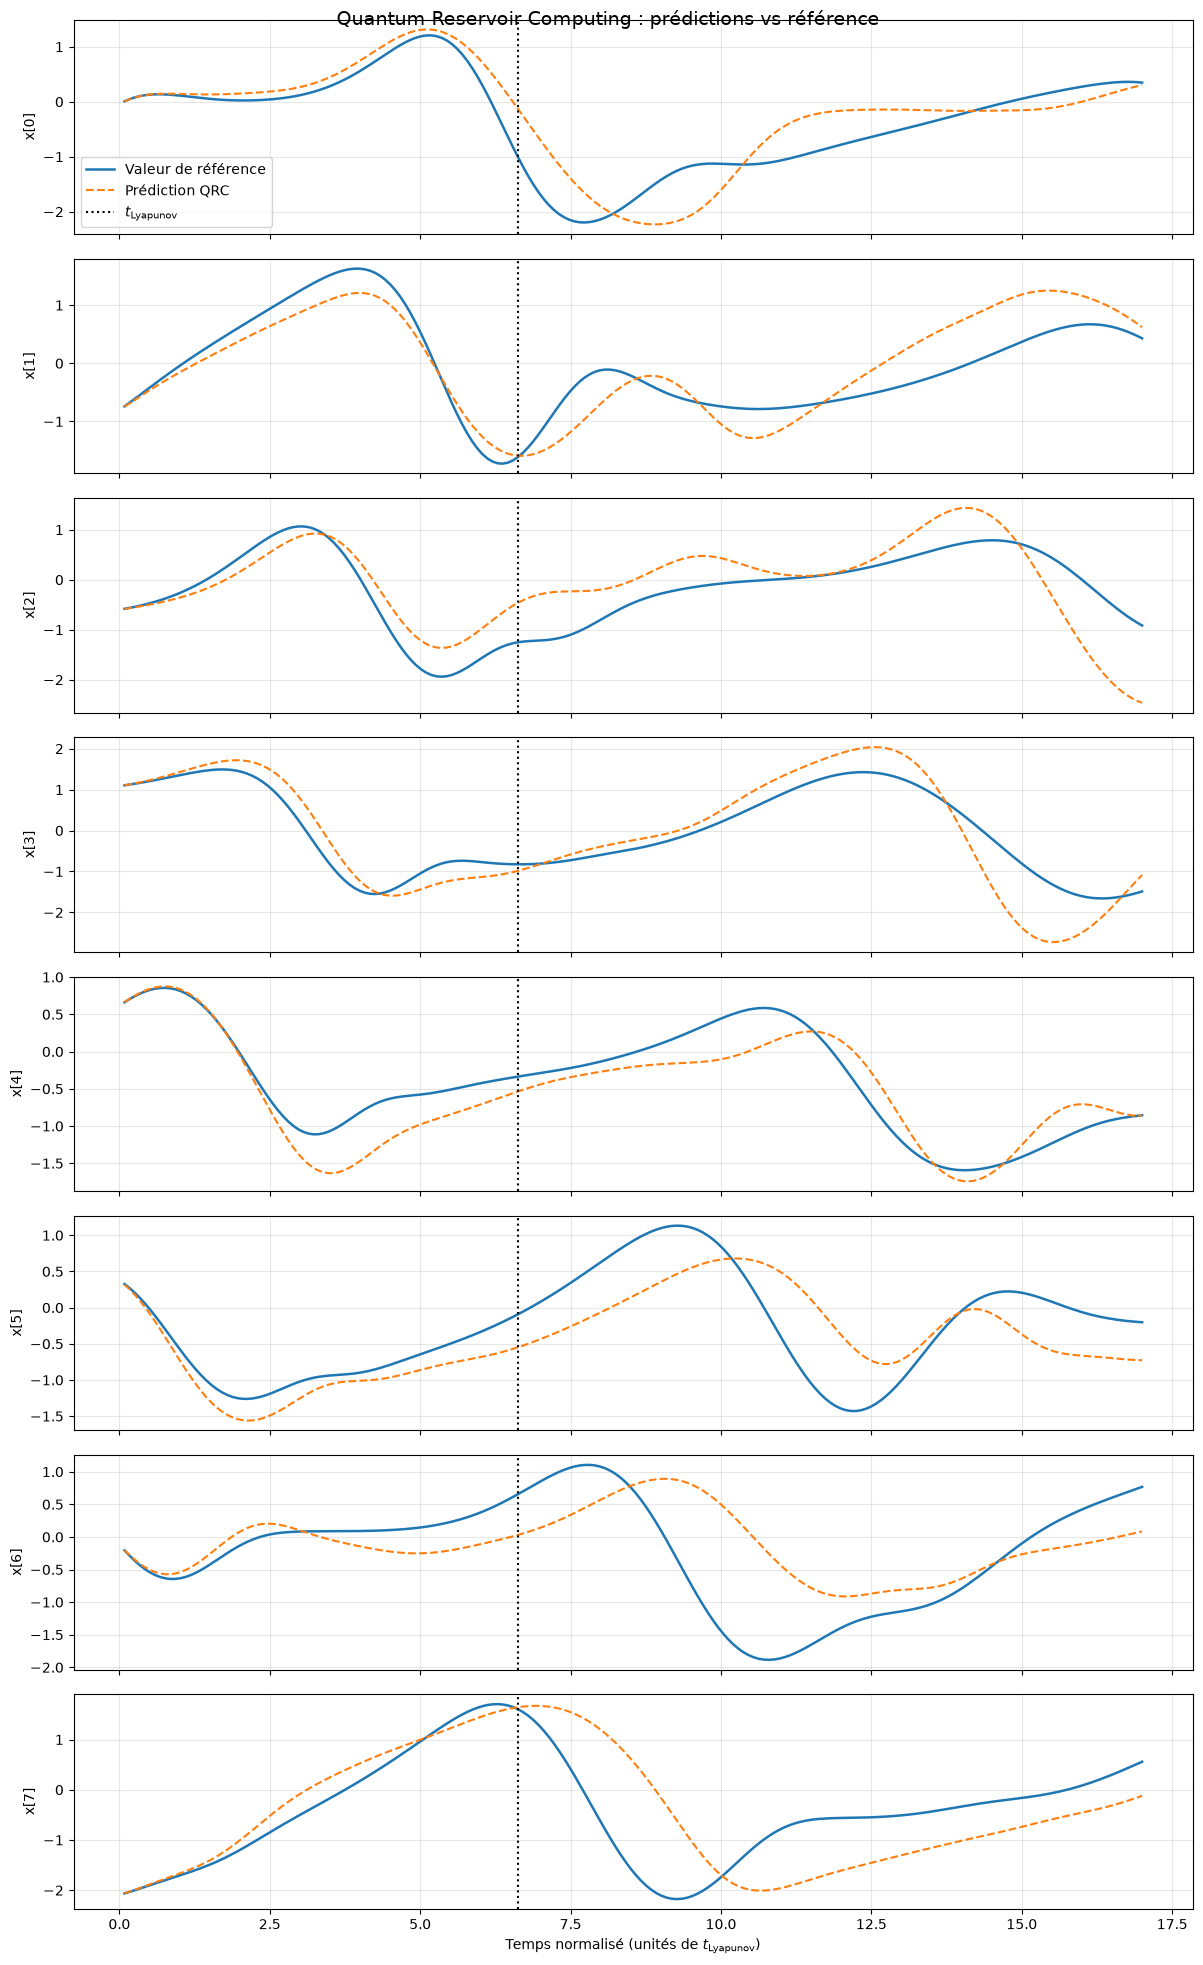

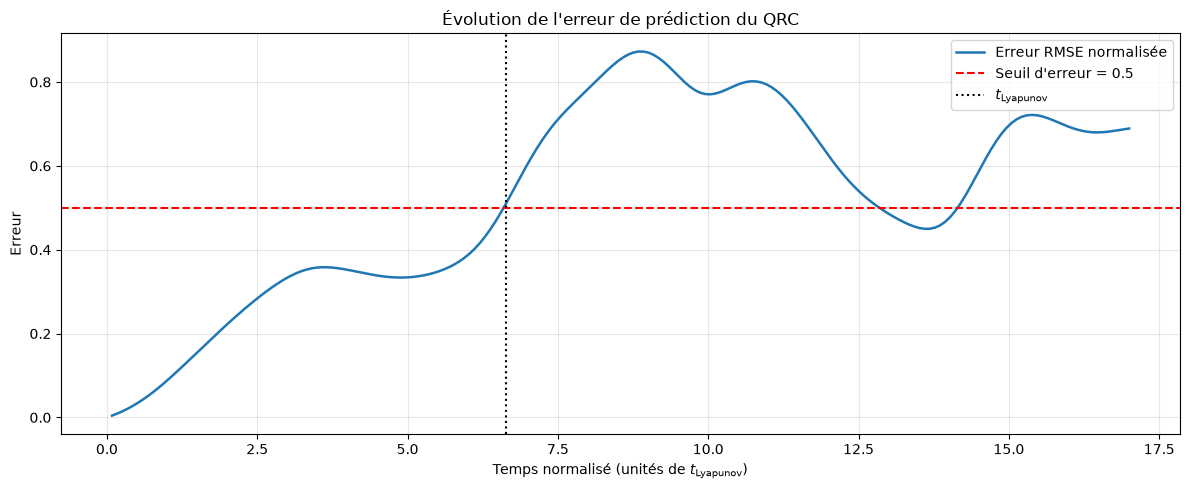

In [31]:

import numpy as np
import matplotlib.pyplot as plt

# Résultats de l'expérience QRC
predictions = results["predictions"]
truth = results["truth"]
t_lyap = results["lyapunov_time"]
error=results["error"]
t_lim=t_lyap[np.flatnonzero(error > 0.5)[0]]

# Vérification des dimensions
assert predictions.shape == truth.shape, (
    f"Dimensions différentes : prédictions {predictions.shape}, "
    f"référence {truth.shape}"
)

n_variables = predictions.shape[1]

# Tracé : une figure par variable
fig, axes = plt.subplots(
    n_variables, 1,
    figsize=(12, 2.5 * n_variables),
    sharex=True
)

# Gérer le cas où il n'y a qu'une seule variable
axes = np.atleast_1d(axes)

for i, ax in enumerate(axes):
    ax.plot(
        t_lyap, truth[:, i],
        label="Valeur de référence",
        linewidth=1.8
    )
    ax.plot(
        t_lyap, predictions[:, i],
        label="Prédiction QRC",
        linestyle="--",
        linewidth=1.5
    )

    # Une unité sur cet axe correspond à un temps de Lyapunov
    ax.axvline(
        x=t_lim,
        color="black",
        linestyle=":",
        linewidth=1.5,
        label=r"$t_{\mathrm{Lyapunov}}$" if i == 0 else None
    )

    ax.set_ylabel(f"x[{i}]")
    ax.grid(True, alpha=0.3)

    if i == 0:
        ax.legend(loc="best")

axes[-1].set_xlabel(
    r"Temps normalisé (unités de $t_{\mathrm{Lyapunov}}$)"
)

fig.suptitle(
    "Quantum Reservoir Computing : prédictions vs référence",
    fontsize=14
)
plt.tight_layout()
plt.show()


# Calcul et tracé de l'erreur de prédiction

plt.figure(figsize=(12, 5))
plt.plot(t_lyap, error, label="Erreur RMSE normalisée", linewidth=1.8)

# Seuil d'erreur utilisé pour définir le temps de prédiction valide
plt.axhline(y=0.5, color="red", linestyle="--", label="Seuil d'erreur = 0.5")

# Un temps de Lyapunov
plt.axvline(x=t_lim, color="black", linestyle=":", label=r"$t_{\mathrm{Lyapunov}}$")

plt.xlabel(r"Temps normalisé (unités de $t_{\mathrm{Lyapunov}}$)")
plt.ylabel("Erreur")
plt.title("Évolution de l'erreur de prédiction du QRC")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


Param essentiels :
alpha de ridge
lambda